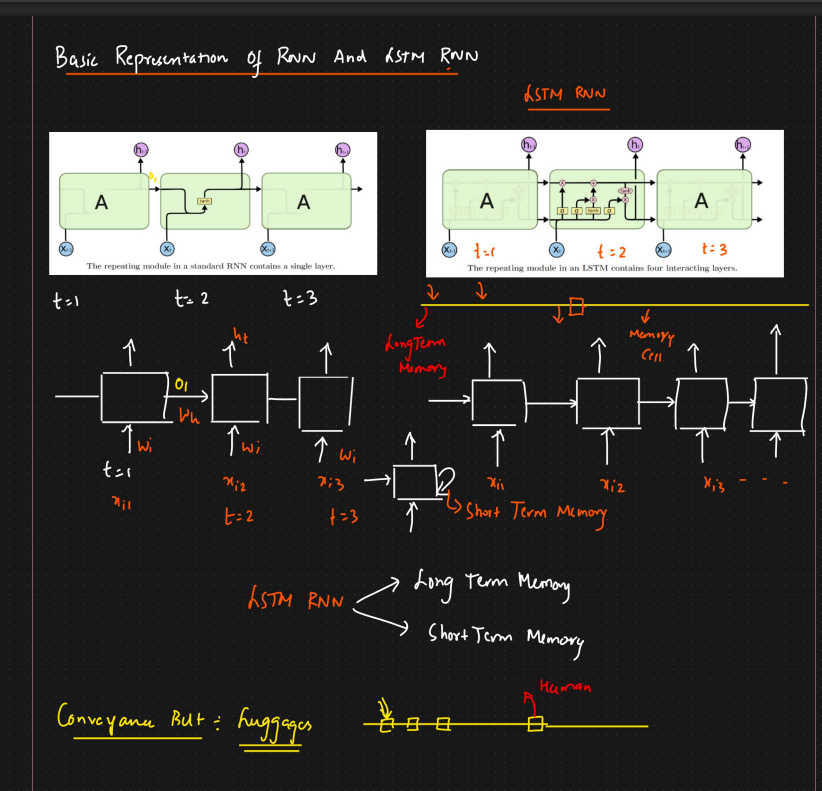

## Basic Architecture of LSTM RNN: 

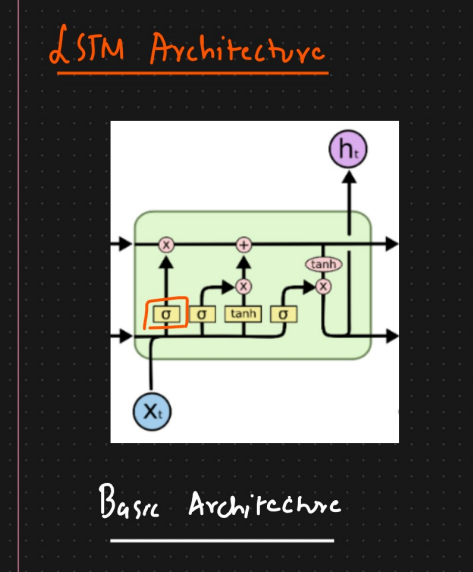 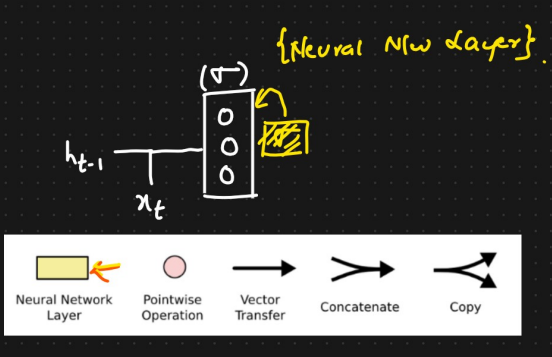


The basic architecture representation includes inputs denoted as $x_t$, which are passed with respect to time. For example, at $t=1$, one word is passed; at $t=2$, another word is passed, and so forth.

---

## Full Architecture of LSTM RNN

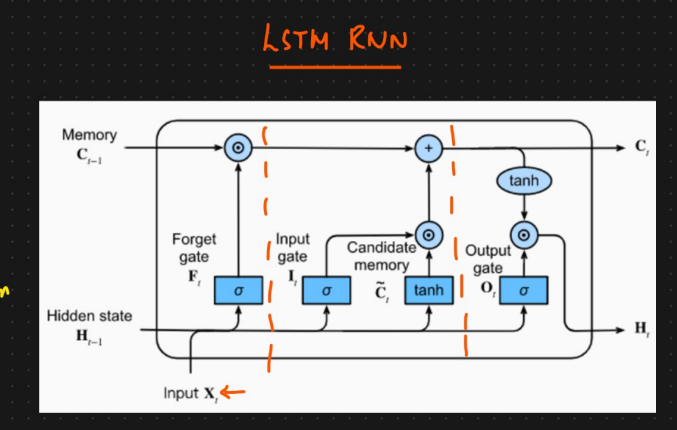

### Core Components of LSTM RNN

The entire LSTM RNN has three important gates:

1. **Forget Gate**
2. **Input Gate and Candidate Memory**
3. **Output Gate**

A single hidden neuron in an LSTM RNN comprises these three gates.

### Inputs and Feedback Loops

At each timestamp, the inputs include:

- **Current input:** $x_t$
- **Previous hidden state:** $h_{t-1}$

These are combined and passed through a sigmoid activation function. Unlike a simple RNN that has one feedback loop, the LSTM RNN has an additional feedback loop that acts as long-term memory.

- $h_{t-1}$ represents the short-term memory (hidden state) from the previous timestamp.
- The additional feedback loop corresponds to the long-term memory stored in the memory cell.

---

### Neural Network Layer Notation

In diagrams, a neural network operator layer is represented where activation functions such as sigmoid or tanh are applied. This layer can be considered as a hidden neuron or hidden layer neuron with an activation function applied to its inputs.

For example, the combined input of $x_t$ and $h_{t-1}$ is passed to this neural network layer with a sigmoid activation.

## Pointwise Operations

Several pointwise operations are used in LSTM computations:

- **Pointwise Multiplication:** Each element of one vector is multiplied by the corresponding element of another vector.
- **Pointwise Addition:** Each element of one vector is added to the corresponding element of another vector.
- **Pointwise tanh:** The hyperbolic tangent function is applied element-wise to a vector.

For example, given vectors $v_1 = [1, 2, 3]$ and $v_2 = [4, 5, 6]$:

- **Pointwise multiplication:** $[1 \times 4, 2 \times 5, 3 \times 6] = [4, 10, 18]$
- **Pointwise addition:** $[1 + 4, 2 + 5, 3 + 6] = [5, 7, 9]$
- **Pointwise tanh:** $\tanh$ is applied to each element individually.

These operations are fundamental in LSTM gate computations and memory cell updates.

## Vector Transfer and Concatenation

- **Vector Transfer:** Arrows in diagrams represent the transfer of vectors from one state to another.

- **Concatenation:** Combining two vectors by appending one after the other, not by adding.

    For example, if $h_{t-1} = [1, 2, 3]$ and $x_t = [2, 3, 4]$, concatenation results in $[1, 2, 3, 2, 3, 4]$, which is then passed as input to the next layer.
    
    eg: $x_t$ and $h_{t-1}$ are concatenated and sent as input to forget gate ([See LSTM Architecture Diagram above]) 
---

### Copy Operation

Copying refers to duplicating a vector to another location or variable, essentially making a duplicate copy of the vector.

## Memory Cell in LSTM

The memory cell represents the long-term memory in the LSTM. It stores information that should be retained or discarded over time.

- $C_{t-1}$ is the memory cell state from the previous timestamp.
- $C_t$ is the updated memory cell state after removing some context and adding new context at the current timestamp.

The memory cell is crucial for maintaining long-term dependencies in sequences.

## Forget Gate in LSTM: Example and Functionality


![forget_gate.png](images/forget_gate.png)

--- 


Let's consider a use case where we have text data and want to predict the next word. For every word in the sequence, such as $X_{11}$, $X_{12}$, $X_{13}$, $X_{14}$, the goal is to predict the next word $Y_{15}$.

Each word is converted into a vector representation (e.g., [0, 2, 4, 6]). These vectors serve as the input at each timestamp.

### Input Dimensions and Concatenation

- Input at time $t$: $x_t$ (e.g., 3D vector)
- Previous hidden state: $h_{t-1}$ (3D vector)
- Previous cell state: $c_{t-1}$ (same dimension as hidden state)

We concatenate $h_{t-1}$ and $x_t$ to form a combined input vector (e.g., 7D if $h_{t-1}$ is 3D and $x_t$ is 4D). This is input to the forget gate's neural network layer.

---

### Neural Network Layer in the Forget Gate

The concatenated input vector is passed through a neural network layer with hidden neurons (e.g., 3). The operation is:

$$
f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)
$$

where $W_f$ is the weight matrix, $b_f$ is the bias, and $f_t$ is the forget gate output.

### Point-wise Multiplication with Previous Cell State

The forget gate output $f_t$ is multiplied point-wise with the previous cell state $c_{t-1}$:

- If $f_t = [0, 0, 0]$, $c_t = [0, 0, 0]$ (all info forgotten)
- If $f_t = [1, 1, 1]$, $c_t = [6, 8, 9]$ (all info retained)
- If $f_t = [0.5, 1, 0.5]$, $c_t = [3, 8, 4.5]$ (partial forgetting)

$$
c_t = f_t \odot c_{t-1}
$$

where $\odot$ denotes point-wise multiplication.

---

### Summary (Short)

The forget gate in LSTM decides which information from the previous cell state to keep or discard by multiplying the cell state with a gate output (values between 0 and 1). This selective forgetting enables LSTMs to manage long-term dependencies in sequences.

## Input Gate and Candidate Memory in LSTM

The **input gate** is similar to the forget gate. It takes the concatenated vector of $x_t$ and $h_{t-1}$ and passes it through its own neural network with weights $W_i$ and bias $b_i$. After sigmoid activation, it produces $i_t$:

$$
i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)
$$

This gate determines which new information will be added to the cell state.

### Candidate Memory

The candidate memory is generated by combining $h_{t-1}$ and $x_t$, but uses a tanh activation function with weights $W_c$ and bias $b_c$:

$$
\tilde{C}_t = \tanh(W_c \cdot [h_{t-1}, x_t] + b_c)
$$

This contains new candidate values for the cell state.

### Example

- If $h_{t-1}$ is 3D and $x_t$ is 4D, their concatenation is 7D.
- Passing through a hidden layer with 3 neurons and tanh yields a 3D candidate memory, e.g., $[0, 1, 0]$.
- The input gate $i_t$ outputs a vector after sigmoid, e.g., $[0.3, 0.8, 0.1]$.

### Combining Input Gate and Candidate Memory

The input gate and candidate memory are combined via pointwise multiplication:

$$
i_t \ast \tilde{C}_t
$$

This filters the candidate memory, deciding what new information to add.

### Updating the Cell State

The cell state $C_t$ is updated by combining the previous cell state (filtered by the forget gate) and new candidate information (filtered by the input gate):

$$
C_t = f_t \ast C_{t-1} + i_t \ast \tilde{C}_t
$$

Here, $\ast$ denotes pointwise multiplication.

---

### Intuition

- The input gate controls the flow of new information into the memory cell.
- The candidate memory represents new information that could be added.
- The forget gate decides what to discard, and the input gate decides what to add.

**Summary:**  
The forget gate $f_t$ decides what to forget, the input gate $i_t$ decides what to add, and the candidate memory $\tilde{C}_t$ contains new values. The cell state $C_t$ is updated by forgetting some old information and adding new information:

$$
C_t = f_t \ast C_{t-1} + i_t \ast \tilde{C}_t
$$

This mechanism allows LSTM networks to maintain and update long-term dependencies effectively.

![input_gate.png](images/input_gate.png)

## Output Gate in LSTM

The output gate uses a sigmoid activation function. It takes the current input $x_t$, previous hidden state $h_{t-1}$, adds a bias $b_0$, and applies the sigmoid function to produce the output gate activation $o_t$:

$$
o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_0)
$$

After this, the output gate multiplies $o_t$ element-wise with the hyperbolic tangent of the memory cell $C_t$:

$$
h_t = o_t \odot \tanh(C_t)
$$

- $h_t$ is the hidden state (short-term memory), passed to the next time step.
- $C_t$ is the memory cell (long-term memory), updated by the forget and input gates.

### Training

Weights for the input gate ($W_i$), candidate memory ($W_c$), and output gate ($W_o$) are updated during training via backpropagation.

### Summary (Short)

- The forget gate removes old information.
- The input gate and candidate memory add new information.
- The output gate controls what part of the memory cell is exposed as the hidden state (short-term memory).

This mechanism allows LSTM to maintain both short-term and long-term memory, enabling effective learning of sequential data.

![output_gate.png](images/output_gate.png)